In [2]:
# Visualize and Compare Activation Functions
# o Train the same MLP using Sigmoid, Tanh, and ReLU.
# o Plot training speed, accuracy, and gradient flow.
# o Discuss vanishing/exploding gradient issues

In [3]:
# Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import time
import numpy as np

I0000 00:00:1794473887.584184    6068 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794473887.651764    6068 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794473891.599251    6068 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Load and preprocess Fashion-MNIST using Pandas
train = pd.read_csv("dataset/Fashion/fashion-mnist_train.csv")
test = pd.read_csv("dataset/Fashion/fashion-mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Missing values:", train.isnull().sum().sum())

Training data: (60000, 784)
Testing data: (10000, 784)
Missing values: 0


In [5]:
# Build and train 3 MLP Model
histories = []
results = []
times = []
models = []

for activation in ['sigmoid', 'tanh', 'relu']:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(64, activation=activation),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    start = time.time()
    history = model.fit(x_train, y_train, epochs=5, batch_size=64,
                        validation_split=0.1, verbose=1)
    times.append(time.time() - start)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    histories.append(history)
    results.append(accuracy)
    models.append(model)

    print(activation, "Accuracy:", accuracy * 100, "%")
    print("Training time:", round(times[-1], 2), "seconds")

E0000 00:00:1794473926.895756    6068 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794473927.681056    6068 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.7630 - loss: 0.7334 - val_accuracy: 0.8282 - val_loss: 0.4843
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8486 - loss: 0.4246 - val_accuracy: 0.8523 - val_loss: 0.4227
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8641 - loss: 0.3785 - val_accuracy: 0.8572 - val_loss: 0.3880
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.8734 - loss: 0.3514 - val_accuracy: 0.8647 - val_loss: 0.3747
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.8804 - loss: 0.3335 - val_accuracy: 0.8682 - val_loss: 0.3591
sigmoid Accuracy: 87.29000091552734 %
Training time: 74.7 seconds
Epoch 1/5


W0000 00:00:1794474004.048359    6068 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.8201 - loss: 0.5002 - val_accuracy: 0.8553 - val_loss: 0.4092
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8622 - loss: 0.3788 - val_accuracy: 0.8600 - val_loss: 0.3839
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8755 - loss: 0.3438 - val_accuracy: 0.8720 - val_loss: 0.3542
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8835 - loss: 0.3181 - val_accuracy: 0.8817 - val_loss: 0.3333
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8885 - loss: 0.3014 - val_accuracy: 0.8792 - val_loss: 0.3334
tanh Accuracy: 87.95999884605408 %
Training time: 68.32 seconds
Epoch 1/5


W0000 00:00:1794474073.773688    6068 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8141 - loss: 0.5251 - val_accuracy: 0.8535 - val_loss: 0.4116
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8614 - loss: 0.3817 - val_accuracy: 0.8608 - val_loss: 0.3811
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8750 - loss: 0.3431 - val_accuracy: 0.8698 - val_loss: 0.3513
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8839 - loss: 0.3168 - val_accuracy: 0.8722 - val_loss: 0.3522
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8894 - loss: 0.2968 - val_accuracy: 0.8773 - val_loss: 0.3399


W0000 00:00:1794474140.253970    6068 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


relu Accuracy: 87.76999711990356 %
Training time: 66.59 seconds


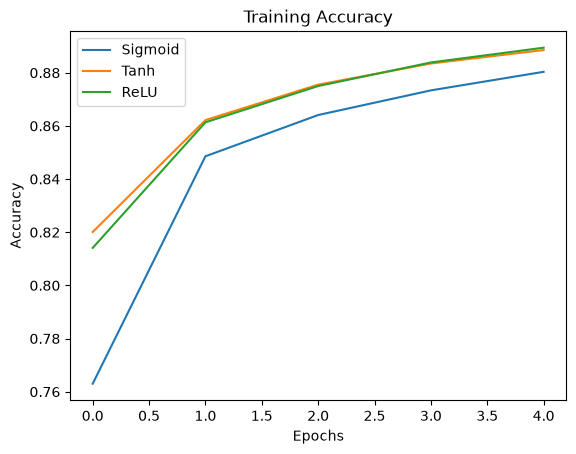

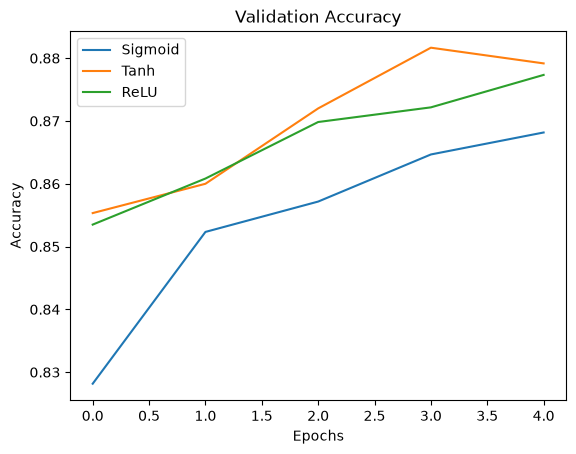

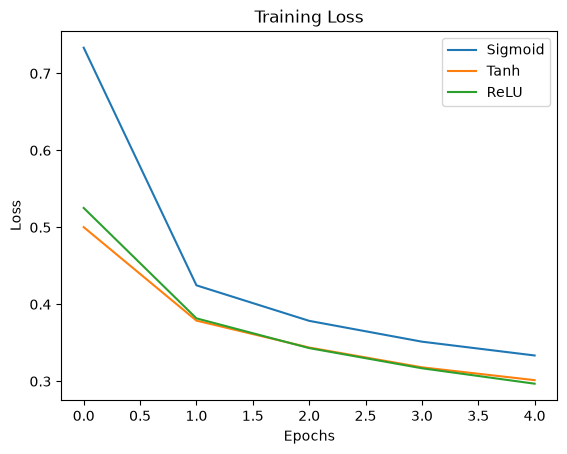

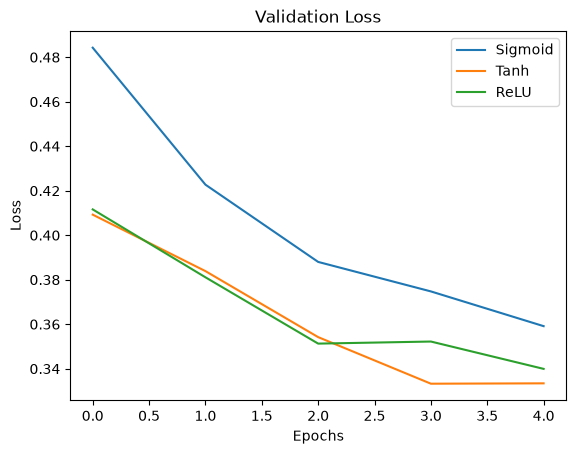

In [6]:
# Compare training and validation accuracy
for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=['Sigmoid', 'Tanh', 'ReLU'][i])

plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_accuracy'], label=['Sigmoid', 'Tanh', 'ReLU'][i])

plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Compare training and validation loss

for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=['Sigmoid', 'Tanh', 'ReLU'][i])

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_loss'], label=['Sigmoid', 'Tanh', 'ReLU'][i])

plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

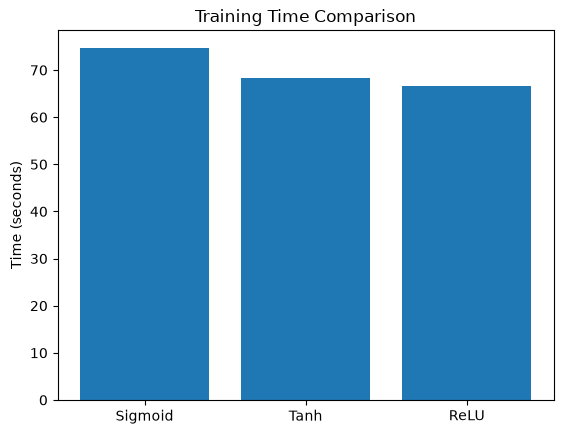

Sigmoid Test Accuracy: 87.29 %
Tanh Test Accuracy: 87.96 %
ReLU Test Accuracy: 87.77 %


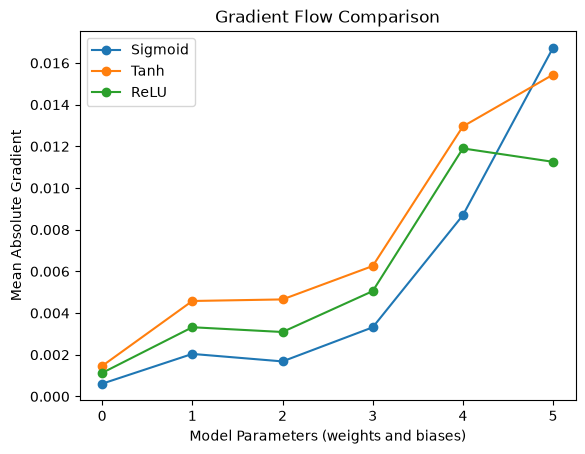

In [8]:
names = ['Sigmoid', 'Tanh', 'ReLU']

plt.bar(names, times)
plt.title("Training Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()

for name, acc in zip(names, results):
    print(name, "Test Accuracy:", round(acc * 100, 2), "%")

# Calculate actual gradients for each trained model
gradient_values = []

for model in models:
    with tf.GradientTape() as tape:
        predictions = model(x_train[:64], training=True)
        loss = tf.keras.losses.sparse_categorical_crossentropy(y_train[:64], predictions)
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)
    gradient_values.append([tf.reduce_mean(tf.abs(g)).numpy() for g in gradients])

for i, values in enumerate(gradient_values):
    plt.plot(values, marker='o', label=names[i])

plt.title("Gradient Flow Comparison")
plt.xlabel("Model Parameters (weights and biases)")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.show()